# Memory X-Ray: explore the results (CPU only)

This notebook reads the **saved** results of the full experiment. It needs no GPU, no model download
and no API key, and runs in well under a minute. Nothing here changes a saved file.

**Research question.** When Phi-3-mini says which evidence records its answer relied on, are those the
records that actually move its answer?

Read every number with three cautions:
1. **Behavioral, not mechanistic.** Shapley values, leave-one-out, necessity and sufficiency describe how
   the model's *output* changes when records are removed. They are not a view of its internal computation.
2. **n = 6 scenarios.** Each scenario is scored on 16 evidence subsets × 3 fixed orderings = 48 prompts.
   These 288 prompts are deterministic, structured measurements, not independent samples. Ranges across
   orderings show sensitivity to order; they are not confidence intervals.
3. **Pre-registered vs post hoc.** Analyses defined after the data were seen are labeled *post hoc*.

In [1]:
# Setup: find the repository root (or clone it, e.g. in a fresh Colab runtime).
import json, os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/FarnooshMemari/memory-xray"   # update if the repository name differs

def find_root():
    for p in (Path.cwd(), Path.cwd().parent):
        if (p / "results" / "report_numbers.json").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "memory-xray"], check=True)
    return Path("memory-xray").resolve()

ROOT = find_root()
os.chdir(ROOT)
load = lambda rel: json.loads((ROOT / rel).read_text())
R = load("results/reanalysis.json")                        # independent recomputation of every quantity
N = load("results/report_numbers.json")                    # every number in the report
B = load("results/post_hoc/content_only_baseline.json")    # POST HOC content-only baseline
M = load(f"runs/{R['run_id']}/manifest.json")              # the run's manifest
P, H = N["pre_registered"], N["post_hoc"]
ORDER = ["s_single", "s_redundant", "s_conflict", "macro_a", "macro_b", "macro_c"]
NAMES = dict(zip(ORDER, ["S-single", "S-redundant", "S-conflict", "Macro A", "Macro B", "Macro C"]))
print("run:", R["run_id"], "| model:", M["scorer"]["model_name"], "@", M["scorer"]["commit_hash"][:8])

run: full_20261017T223452Z | model: microsoft/Phi-3-mini-4k-instruct @ f39ac1d2


In [2]:
from IPython.display import Markdown, Image, display

def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

f3 = lambda x: "n/a" if x is None else f"{x:.3f}"

## 1. What the model sees

Each scenario has a question and four evidence records (E1–E4). Every subset of the records is shown in three
fixed orderings, with opaque IDs (e.g. `[R7]`) re-mapped per ordering. The model's answer is scored as the
probability of ` Positive` / ` Neutral` / ` Negative` after the forced prefix `Signal:`. Here is the full-evidence
prompt for the conflict control in ordering 0:

In [3]:
cells = [json.loads(l) for l in (ROOT / "runs" / R["run_id"] / "s_conflict" / "cells.jsonl").read_text().splitlines()]
first = next(c for c in cells if c["ordering"] == 0 and c["subset"] == "E1+E2+E3+E4")
print(first["user_msg"])
print("\nshown IDs -> records:", dict(zip(first["shown_ids"], first["shown_canonical"])))

You are a macro-financial analyst. Read the question and the evidence records, then give a signal.
Base your answer only on the evidence records below. If the records do not settle the question, answer Neutral.

Question: Using the decision rule below, classify the 12-month signal for Economy M's equity market. Decision rule: the central bank's most recent policy-rate decision takes precedence over everything else. A rate cut means Positive and a rate hike means Negative. Only if no policy-rate decision is reported, use the latest inflation report instead: inflation above the central bank's target means Negative and inflation below the target means Positive. If neither is reported, the signal is Neutral.

Evidence records:
[R7] At its most recent meeting, Economy M's central bank cut its policy rate by 25 basis points.
[R3] The latest inflation report shows Economy M's consumer prices rising 5.8% a year, well above the central bank's 2% target.
[R9] Economy M's securities regulator ren

In [4]:
rows = []
for sid in ORDER:
    sc = load(f"scenarios/{sid}.json")
    rows.append([NAMES[sid], "designed control" if sc["kind"] == "synthetic_control" else "realistic (rubric)",
                 sc["structure"], P[sid]["d_star"], P[sid]["reference"]])
table(["Scenario", "Kind", "Structure", "Model decision d*", "Designed / rubric answer"], rows)

| Scenario | Kind | Structure | Model decision d* | Designed / rubric answer |
|---|---|---|---|---|
| S-single | designed control | single_decisive | Positive | Positive |
| S-redundant | designed control | redundant | Negative | Negative |
| S-conflict | designed control | conflict | Positive | Positive |
| Macro A | realistic (rubric) | rubric | Positive | Positive |
| Macro B | realistic (rubric) | rubric | Negative | Negative |
| Macro C | realistic (rubric) | rubric | Negative | Negative |

## 2. Is the measurement sound?

Infrastructure checks I1–I9 (tokenization, numerical precision, greedy agreement, repeatability, pinned model) and
an independent re-implementation that shares no metric, analysis or check code with the pipeline.

In [5]:
rows = []
for sid in ORDER:
    inf, cmp_ = P[sid]["infra"], R["comparison_with_pipeline"][sid]
    rows.append([NAMES[sid], "pass" if all(v for k, v in inf.items() if k.startswith("I")) else "FAIL",
                 f3(inf["_min_label_mass"]), f"{inf['_max_recompute_diff']:.1e}",
                 f"{cmp_['max_abs_diff_shapley']:.1e}", cmp_["checks_equal"] and cmp_["citation_consistency_equal"]])
table(["Scenario", "I1–I9", "Min label mass", "Max recompute diff", "Shapley diff vs re-implementation",
       "Checks & citation scores identical"], rows)

| Scenario | I1–I9 | Min label mass | Max recompute diff | Shapley diff vs re-implementation | Checks & citation scores identical |
|---|---|---|---|---|---|
| S-single | pass | 0.970 | 8.3e-05 | 1.1e-16 | True |
| S-redundant | pass | 0.973 | 3.0e-05 | 2.2e-16 | True |
| S-conflict | pass | 0.970 | 0.0e+00 | 1.1e-16 | True |
| Macro A | pass | 0.979 | 1.4e-05 | 1.1e-16 | True |
| Macro B | pass | 0.979 | 0.0e+00 | 1.1e-16 | True |
| Macro C | pass | 0.979 | 1.1e-04 | 1.1e-16 | True |

## 3. Designed controls: does attribution recover the planted structure?

Shapley values (exact, over all 16 subsets) and leave-one-out (LOO) for the probability of the decision, d*.
Values are means over the three orderings, with the range in brackets.

In [6]:
rng = lambda d: f"{d['mean']:+.3f} [{d['min']:+.3f}, {d['max']:+.3f}]"
for sid in ["s_single", "s_redundant", "s_conflict"]:
    sc = load(f"scenarios/{sid}.json")
    des = sc["designed"]
    roles = des.get("roles") or {**{e: "decisive record" for e in des.get("decisive", [])},
                                 **{e: "directionless distractor" for e in des.get("distractors", [])}}
    ch = P[sid]["checks"]
    status = "all pass" if all(ch.values()) else "FAIL: " + ", ".join(k for k, v in ch.items() if not v)
    display(Markdown(f"**{NAMES[sid]}** (d* = {P[sid]['d_star']}; recovery checks {status})"))
    table(["Record", "Designed role", "Shapley", "Leave-one-out"],
          [[e, roles[e], rng(P[sid]["shapley"][e]), rng(P[sid]["loo"][e])] for e in ["E1", "E2", "E3", "E4"]])

**S-single** (d* = Positive; recovery checks all pass)

| Record | Designed role | Shapley | Leave-one-out |
|---|---|---|---|
| E1 | directionless distractor | -0.000 [-0.000, +0.000] | -0.000 [-0.000, +0.000] |
| E2 | decisive record | +0.999 [+0.999, +0.999] | +0.999 [+0.999, +0.999] |
| E3 | directionless distractor | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] |
| E4 | directionless distractor | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.001] |

**S-redundant** (d* = Negative; recovery checks all pass)

| Record | Designed role | Shapley | Leave-one-out |
|---|---|---|---|
| E1 | official report of the hike (sufficient alone) | +0.477 [+0.474, +0.480] | -0.007 [-0.011, -0.004] |
| E2 | rule-excluded commentary pointing the same way (designed influence 0; tempting to cite) | +0.014 [+0.012, +0.016] | -0.002 [-0.005, +0.002] |
| E3 | second official report of the same hike (sufficient alone) | +0.479 [+0.476, +0.484] | -0.005 [-0.014, +0.007] |
| E4 | directionless distractor | +0.002 [-0.001, +0.007] | +0.004 [-0.001, +0.011] |

**S-conflict** (d* = Positive; recovery checks FAIL: BC1, BC3, BC4, BC5)

| Record | Designed role | Shapley | Leave-one-out |
|---|---|---|---|
| E1 | policy-rate cut; takes precedence (Positive) | +0.712 [+0.653, +0.812] | +0.469 [+0.360, +0.627] |
| E2 | inflation above target; decides only when E1 is absent (Negative) | -0.281 [-0.338, -0.183] | -0.523 [-0.630, -0.368] |
| E3 | directionless distractor | +0.016 [-0.002, +0.027] | +0.033 [-0.048, +0.077] |
| E4 | directionless distractor | +0.028 [+0.003, +0.057] | +0.066 [-0.037, +0.172] |

**Redundancy.** In S-redundant, two official reports each settle the answer alone. Removing either one changes almost
nothing (LOO ≈ 0), so leave-one-out would call both unimportant; Shapley splits the effect between them.

**Conflict.** S-conflict instructs a precedence rule (the rate cut E1 overrides the inflation report E2). The table
below lists every cell that contains both records: the label follows whichever record comes **later**, not the rule.
Only one of the three fixed orderings puts E1 after E2, so this is a single ordering contrast, not a replicated effect.

In [7]:
s = R["scenarios"]["s_conflict"]
rows = []
for o in s["per_ordering"]:
    pos = s["order_positions"][str(o["ordering"])]
    for key, lab in o["argmax"].items():
        if {"E1", "E2"} <= set(key.split("+")):
            later = "E1 (rate cut)" if pos["E1"] > pos["E2"] else "E2 (inflation)"
            rows.append([o["ordering"], key, later, lab, f3(o["v"][key])])
table(["Ordering", "Records shown", "Later of E1/E2", "Model's label", "P(Positive)"], rows)

| Ordering | Records shown | Later of E1/E2 | Model's label | P(Positive) |
|---|---|---|---|---|
| 0 | E1+E2 | E2 (inflation) | Negative | 0.216 |
| 0 | E1+E2+E3 | E2 (inflation) | Negative | 0.302 |
| 0 | E1+E2+E4 | E2 (inflation) | Negative | 0.288 |
| 0 | E1+E2+E3+E4 | E2 (inflation) | Negative | 0.365 |
| 1 | E1+E2 | E2 (inflation) | Negative | 0.206 |
| 1 | E1+E2+E3 | E2 (inflation) | Negative | 0.255 |
| 1 | E1+E2+E4 | E2 (inflation) | Negative | 0.357 |
| 1 | E1+E2+E3+E4 | E2 (inflation) | Negative | 0.427 |
| 2 | E1+E2 | E1 (rate cut) | Positive | 0.553 |
| 2 | E1+E2+E3 | E1 (rate cut) | Positive | 0.668 |
| 2 | E1+E2+E4 | E1 (rate cut) | Positive | 0.678 |
| 2 | E1+E2+E3+E4 | E1 (rate cut) | Positive | 0.631 |

## 4. Realistic scenarios: Shapley values vs an external rubric

The model never sees the rubric. "Rubric-following" is the Shapley value a model that followed the rubric exactly would
show (computed before the run).

In [8]:
rows = []
for sid in ["macro_a", "macro_b", "macro_c"]:
    sc = load(f"scenarios/{sid}.json")
    for e in ["E1", "E2", "E3", "E4"]:
        rows.append([NAMES[sid], e, sc["records"][e][:70] + "…", f"{P[sid]['rubric_ideal_shapley'][e]:+.3f}",
                     rng(P[sid]["shapley"][e]), f"{P[sid]['loo'][e]['mean']:+.3f}"])
table(["Scenario", "Record", "Text (start)", "Rubric-following φ", "Observed φ", "LOO mean"], rows)
ma = P["macro_a"]
print("Macro A full-evidence argmax by ordering:", ma["full_argmax_per_ordering"],
      "| mean P(Pos) - P(Neu) =", f3(ma["mean_full_dist"]["Positive"] - ma["mean_full_dist"]["Neutral"]))

| Scenario | Record | Text (start) | Rubric-following φ | Observed φ | LOO mean |
|---|---|---|---|---|---|
| Macro A | E1 | Economy A's central bank lowered its policy rate by 50 basis points to… | +0.417 | +0.233 [+0.191, +0.283] | +0.187 |
| Macro A | E2 | Core consumer-price inflation in Economy A slowed to 2.4% a year from … | +0.417 | +0.286 [+0.255, +0.318] | +0.184 |
| Macro A | E3 | Economy A's manufacturing purchasing managers' index fell to 47.6, its… | -0.250 | -0.479 [-0.542, -0.418] | -0.507 |
| Macro A | E4 | Analysts raised their consensus forecast for Economy A's listed-compan… | +0.417 | +0.365 [+0.332, +0.393] | +0.179 |
| Macro B | E1 | Economy B's central bank raised its policy rate by 75 basis points to … | +0.417 | +0.231 [+0.167, +0.268] | +0.109 |
| Macro B | E2 | Consumer-price inflation in Economy B rose to 6.8% a year from 5.1% th… | +0.417 | +0.436 [+0.415, +0.469] | +0.240 |
| Macro B | E3 | Economy B's services purchasing managers' index rose to 55.2, its stro… | -0.250 | -0.220 [-0.277, -0.186] | -0.116 |
| Macro B | E4 | Analysts cut their consensus forecast for Economy B's listed-company e… | +0.417 | +0.349 [+0.334, +0.360] | +0.143 |
| Macro C | E1 | Economy C's central bank cut its policy rate by 25 basis points to 3.0… | -0.250 | -0.021 [-0.043, -0.002] | -0.021 |
| Macro C | E2 | Economy C's unemployment rate rose to 6.1% from 4.8% a year earlier, a… | +0.417 | +0.347 [+0.332, +0.361] | +0.065 |
| Macro C | E3 | Spreads on Economy C's corporate bonds widened by 180 basis points ove… | +0.417 | +0.281 [+0.267, +0.298] | +0.038 |
| Macro C | E4 | Analysts cut their consensus forecast for Economy C's listed-company e… | +0.417 | +0.320 [+0.293, +0.352] | +0.049 |

Macro A full-evidence argmax by ordering: ['Neutral', 'Positive', 'Positive'] | mean P(Pos) - P(Neu) = 0.020


## 5. Counterfactual flips (realistic scenarios)

One record is reversed (e.g. a rate cut becomes a rate hike). The probability of the original decision drops in every
cell, but the label changes in only some, so a label-based test understates the effect.

In [9]:
rows = []
for sid in ["macro_a", "macro_b", "macro_c"]:
    for f in P[sid]["flips"]:
        rows.append([NAMES[sid], f["ordering"], f"{f3(f['p_dstar_orig'])} → {f3(f['p_dstar_flip'])}",
                     f"{f['delta_p_dstar']:+.3f}", f"{f['orig_argmax']} → {f['argmax']}"])
table(["Scenario", "Ordering", "P(d*) original → flipped", "ΔP(d*)", "Label"], rows)

| Scenario | Ordering | P(d*) original → flipped | ΔP(d*) | Label |
|---|---|---|---|---|
| Macro A | 0 | 0.236 → 0.069 | -0.167 | Neutral → Neutral |
| Macro A | 1 | 0.554 → 0.205 | -0.348 | Positive → Neutral |
| Macro A | 2 | 0.428 → 0.127 | -0.301 | Positive → Neutral |
| Macro B | 0 | 0.733 → 0.330 | -0.403 | Negative → Neutral |
| Macro B | 1 | 0.844 → 0.366 | -0.478 | Negative → Neutral |
| Macro B | 2 | 0.854 → 0.688 | -0.166 | Negative → Negative |
| Macro C | 0 | 0.934 → 0.398 | -0.536 | Negative → Neutral |
| Macro C | 1 | 0.952 → 0.563 | -0.389 | Negative → Negative |
| Macro C | 2 | 0.937 → 0.494 | -0.444 | Negative → Negative |

## 6. Self-reported citations

After the answer, the model is asked: *"Which evidence records did your answer rely on? Reply with only a JSON list of
the record IDs…"*. Each cited set is compared with every other set of the same size: the **beat fraction** is the share
of alternatives it beats on necessity (removing it lowers P(d*) more) or sufficiency (keeping only it preserves P(d*)
better). Chance = 0.5. Pre-registered metrics, partial citations from sampled replies:

In [10]:
rows = []
for sid in ORDER:
    c = P[sid]["citations"]["all"]
    rows.append([NAMES[sid], c["n_partial"], f3(c["mean_beat_nec"]), f3(c["mean_beat_suf"]), f3(c["mean_topk"]),
                 ", ".join(f"{'[] (empty)' if k == 'none' else k}×{v}" for k, v in P[sid]["citations"]["sampled_sets"].items())])
pc = P["_pooled_citations"]["all"]
rows.append(["**Pooled**", pc["n_partial"], f3(pc["mean_beat_nec"]), f3(pc["mean_beat_suf"]), f3(pc["mean_topk"]), ""])
table(["Scenario", "n partial", "Necessity beat", "Sufficiency beat", "Shapley top-k", "Cited sets (sampled)"], rows)

| Scenario | n partial | Necessity beat | Sufficiency beat | Shapley top-k | Cited sets (sampled) |
|---|---|---|---|---|---|
| S-single | 8 | 1.000 | 1.000 | 1.000 | E2×8 |
| S-redundant | 6 | 0.889 | 0.656 | 1.000 | E1+E3×5, E3×1 |
| S-conflict | 8 | 0.833 | 0.746 | 0.708 | E1+E2×4, E1+E2+E4×1, E1×2, E1+E3×1 |
| Macro A | 5 | 0.780 | 0.800 | 0.800 | E2+E4×1, E1+E2+E4×3, E1+E2+E3+E4×3, E1+E3×1 |
| Macro B | 8 | 0.867 | 0.879 | 0.833 | [] (empty)×1, E1+E2+E3×1, E2+E4×1, E1+E2×2, E1+E2+E4×3, E2×1 |
| Macro C | 5 | 1.000 | 1.000 | 1.000 | E1+E2+E3+E4×2, E2+E3+E4×5 |
| **Pooled** | 40 | 0.896 | 0.848 | 0.883 |  |

**Decision mismatch.** The citation prompt shows the scenario-level decision d* (averaged over orderings). In 3 of 18
scenario-orderings the model's own answer for that ordering was different, so those citations justify a label the model
did not choose. They still beat chance with respect to that label (post hoc split below).

In [11]:
a, m = H["aligned_only_pooled"], H["misaligned_only_pooled"]
table(["Orderings (post hoc split)", "n partial", "Necessity beat", "Sufficiency beat", "Shapley top-k"],
      [["Aligned (own answer = shown label)", a["n_partial"], f3(a["mean_beat_nec"]), f3(a["mean_beat_suf"]), f3(a["mean_topk"])],
       ["Misaligned (own answer ≠ shown label)", m["n_partial"], f3(m["mean_beat_nec"]), f3(m["mean_beat_suf"]), f3(m["mean_topk"])]])
print("misaligned orderings:", {NAMES[s]: P[s]["misaligned_orderings"] for s in ORDER if P[s]["misaligned_orderings"]})

| Orderings (post hoc split) | n partial | Necessity beat | Sufficiency beat | Shapley top-k |
|---|---|---|---|---|
| Aligned (own answer = shown label) | 32 | 0.908 | 0.877 | 0.927 |
| Misaligned (own answer ≠ shown label) | 8 | 0.846 | 0.733 | 0.708 |

misaligned orderings: {'S-conflict': [0, 1], 'Macro A': [0]}


## 7. Post hoc: a citer that never looks at the model

A fixed rule that cites the records whose *content* supports the answer (the designed set in the controls; the records
whose rubric score has the sign of the reference answer in the realistic scenarios), scored with the same metrics against
the model's own behavior. **Defined after the results were seen; exploratory.**

In [12]:
rows = []
for sid in ORDER:
    c, mdl = B["scenarios"][sid]["content_only"], B["scenarios"][sid]["model_pre_registered"]
    rows.append([NAMES[sid], "+".join(B["scenarios"][sid]["content_only_set"]),
                 f"{f3(c['mean_beat_nec'])} / {f3(c['mean_beat_suf'])} / {f3(c['mean_topk'])}",
                 f"{f3(mdl['mean_beat_nec'])} / {f3(mdl['mean_beat_suf'])} / {f3(mdl['mean_topk'])}"])
table(["Scenario", "Content-only set", "Content-only nec / suf / top-k", "Model nec / suf / top-k"], rows)
cmp_ = B["pooled"]["scenario_metric_comparisons"]
print(f"content-only >= model in {cmp_['content_only_ge_model']}/{cmp_['of']} scenario x metric comparisons; exceptions:",
      [(e["scenario"], e["metric"], round(e["content_only"], 3), round(e["model"], 3)) for e in cmp_["exceptions"]])

| Scenario | Content-only set | Content-only nec / suf / top-k | Model nec / suf / top-k |
|---|---|---|---|
| S-single | E2 | 1.000 / 1.000 / 1.000 | 1.000 / 1.000 / 1.000 |
| S-redundant | E1+E3 | 1.000 / 0.633 / 1.000 | 0.889 / 0.656 / 1.000 |
| S-conflict | E1 | 1.000 / 1.000 / 1.000 | 0.833 / 0.746 / 0.708 |
| Macro A | E1+E2+E4 | 1.000 / 1.000 / 1.000 | 0.780 / 0.800 / 0.800 |
| Macro B | E1+E2+E4 | 1.000 / 1.000 / 1.000 | 0.867 / 0.879 / 0.833 |
| Macro C | E2+E3+E4 | 1.000 / 1.000 / 1.000 | 1.000 / 1.000 / 1.000 |

content-only >= model in 17/18 scenario x metric comparisons; exceptions: [('s_redundant', 'mean_beat_suf', 0.633, 0.656)]


**Reading this.** Citing the records whose content supports the answer is enough to score as well as the model on these
metrics. So high citation scores show the model can *name records that push toward a given label*; on their own they are
not evidence that it reports what drove its own decision.

## 8. Figures

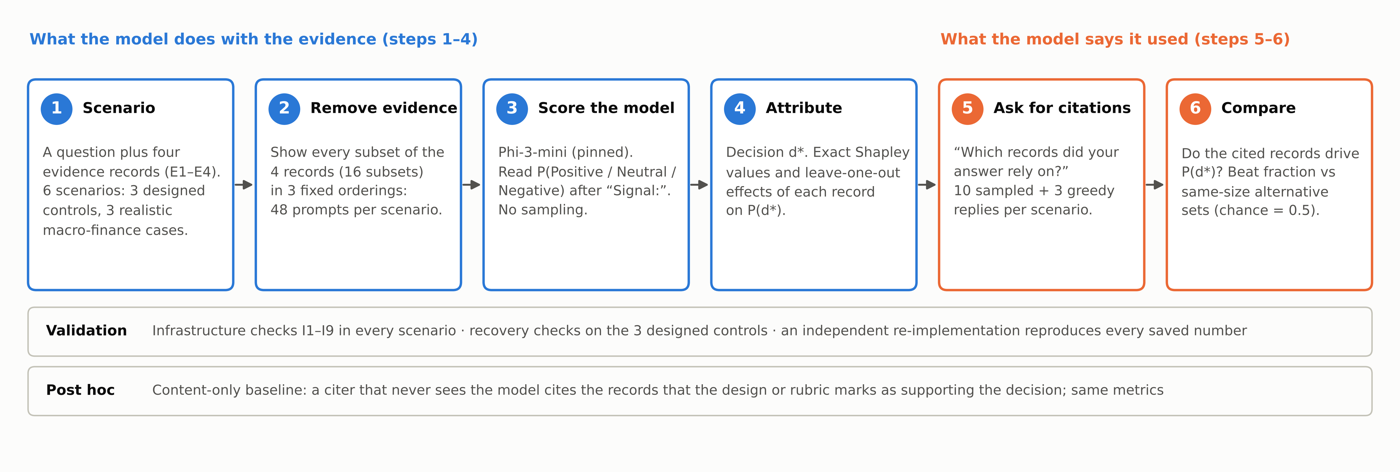

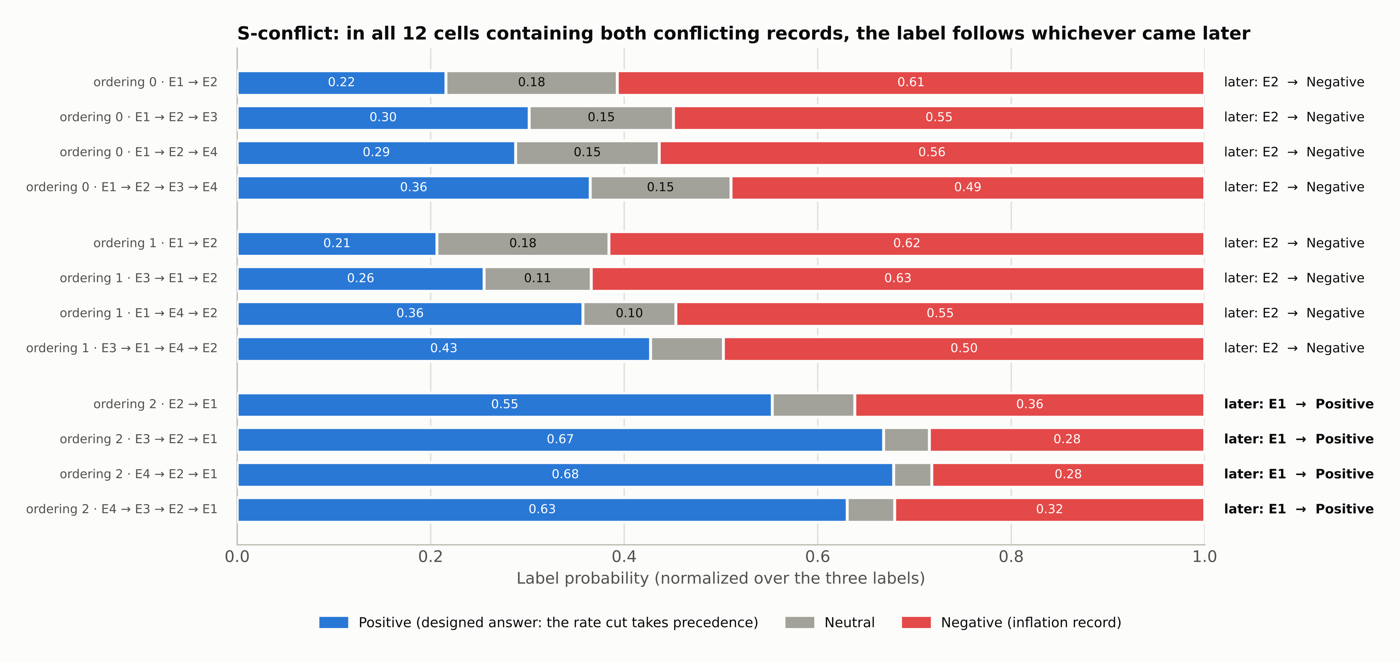

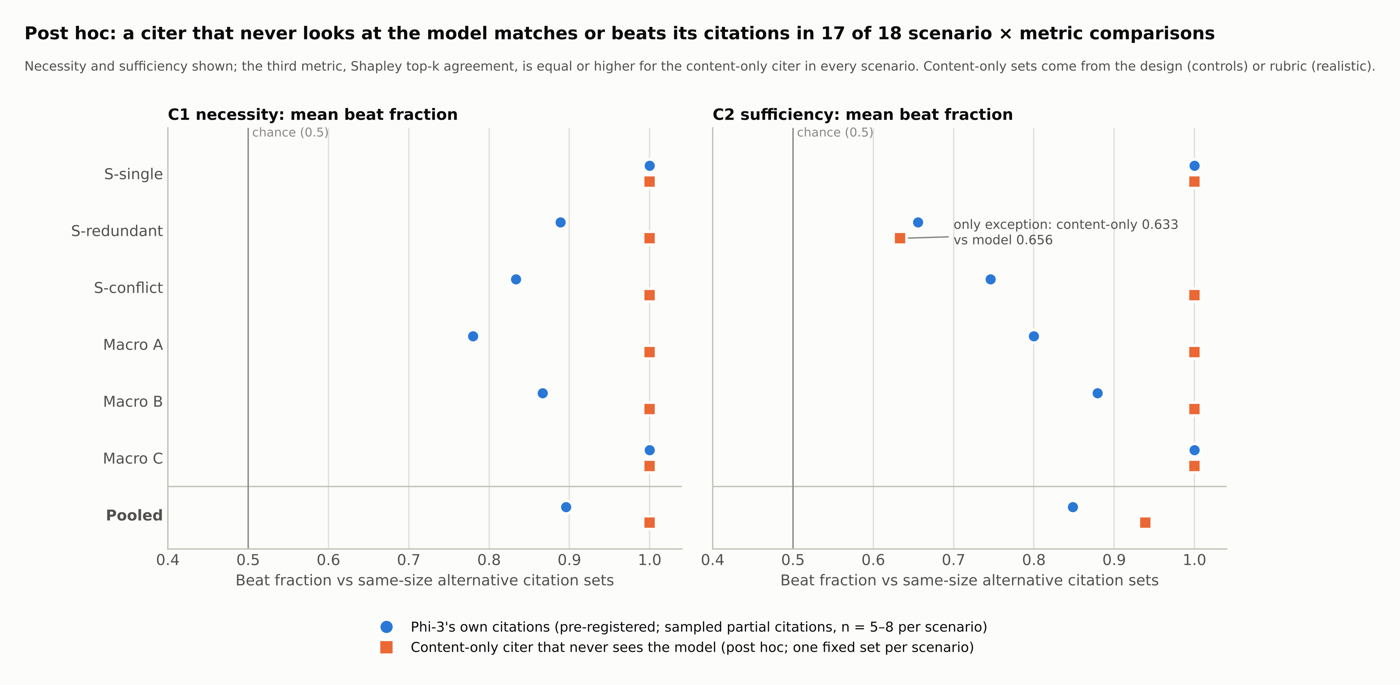

In [13]:
import io
from PIL import Image as PILImage            # installed with matplotlib

def show(name, width=1400):                  # downscaled copy keeps the notebook small; full-size files are in the repo
    im = PILImage.open(ROOT / "results/figures/publication" / f"{name}.png").convert("RGB")
    im.thumbnail((width, width * 4))
    buf = io.BytesIO(); im.save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue(), width=900))

for name in ["fig0_workflow", "fig3_s_conflict_ordering_effect", "fig8_content_only_baseline"]:
    show(name)

## 9. Check it yourself

`scripts/verify_release.py` re-runs the independent reanalysis, the report numbers and the post hoc baseline in a
temporary copy and compares them with the committed files; it also checks every checksum and recomputes the pipeline's
checks. It takes about half a minute and changes nothing.

In [14]:
r = subprocess.run([sys.executable, "scripts/verify_release.py"], capture_output=True, text=True)
print((r.stdout or r.stderr).replace(str(ROOT), "<repository>"))

Verifying <repository> with Python 3.13.15

[PASS] 1 original package files preserved: 160/160 accounted for: 158 byte-identical at their release paths, 2 edited for the public release and matching their recorded SHA-256 (results/RESULTS_AND_DISCUSSION.md, results/RESULTS_AND_DISCUSSION.html); 3 replaced in the release (documented in CHANGES.md): reanalyze.py, tests/test_precision.py, requirements.txt
[PASS] 2 saved runs and labels match their checksums: 89/89 files verified
[PASS] 3a frozen scenario files and design fingerprints: FREEZE OK: all frozen files match
[PASS] 3b rubric label gate (G2): Agreement: labeler_1_vs_frozen 15/15, labeler_2_vs_frozen 15/15, labeler_1_vs_labeler_2 15/15
[PASS] 4 run analysis_full/independent_reanalysis.py: exit 0, printed 'INDEPENDENT REANALYSIS AGREES WITH PIPELINE: True'
[PASS] 4 run analysis_full/report_numbers.py: exit 0
[PASS] 4 run analysis_full/content_only_baseline.py: exit 0
[PASS] 4 regenerated results/reanalysis.json equals committed: equ